In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
from astropy.io import fits
from matplotlib import pyplot as plt

ROOT = Path.cwd()
FITS_DIR = ROOT / "fits_ready"
FIGS_DIR = ROOT / "Imgs"
FIGS_DIR.mkdir(exist_ok=True)


In [2]:
# -------------------------------------------------------
# MUSE 30 Doradus Halpha datasets
# -------------------------------------------------------

BINS = tuple(range(6))

DATASET_PREFIX = "SAMFP-30Dor-H"
SUFFIX = "-ivsv"

datasets = [
    {
        "instrument": "SAMFP",
        "bin": bin_level,
        "line": "Halpha",
        "filename": f"{DATASET_PREFIX}-bin{bin_level}{SUFFIX}.fits",
        "label": rf"${2**bin_level}\times{2**bin_level}$",
    }
    for bin_level in BINS
]

pd.DataFrame(datasets)


,instrument,bin,line,filename,label
0,SAMFP,0,Halpha,SAMFP-30Dor-H-bin0-ivsv.fits,$1\times1$
1,SAMFP,1,Halpha,SAMFP-30Dor-H-bin1-ivsv.fits,$2\times2$
2,SAMFP,2,Halpha,SAMFP-30Dor-H-bin2-ivsv.fits,$4\times4$
3,SAMFP,3,Halpha,SAMFP-30Dor-H-bin3-ivsv.fits,$8\times8$
4,SAMFP,4,Halpha,SAMFP-30Dor-H-bin4-ivsv.fits,$16\times16$
5,SAMFP,5,Halpha,SAMFP-30Dor-H-bin5-ivsv.fits,$32\times32$


In [3]:
def load_velocity_dataset(entry):
    fits_path = FITS_DIR / entry["filename"]

    if not fits_path.exists():
        raise FileNotFoundError(f"Missing FITS file: {fits_path}")

    with fits.open(fits_path) as hdul:
        sb = hdul["MOM0"].data.astype(float)
        vv = hdul["MOM1"].data.astype(float)

    yy, xx = np.indices(vv.shape)

    df = pd.DataFrame({
        "X": xx.ravel(),
        "Y": yy.ravel(),
        "VV": vv.ravel(),
        "SB": sb.ravel(),
    })

    df = df.dropna(subset=["VV", "SB"])

    df["instrument"] = entry["instrument"]
    df["line"] = entry["line"]
    df["label"] = entry["label"]
    df["filename"] = entry["filename"]
    df["bin"] = entry["bin"]

    mean_v = df["VV"].mean()
    df["RV_centered"] = df["VV"] - mean_v

    raw = {
        "sb": sb,
        "vv": vv,
        "instrument": entry["instrument"],
        "line": entry["line"],
        "label": entry["label"],
        "filename": entry["filename"],
        "bin": entry["bin"],
    }

    return df, raw


In [4]:
processed_list = []
raw_data = {}

for entry in datasets:
    df, raw = load_velocity_dataset(entry)
    processed_list.append(df)

    key = (entry["line"], entry["instrument"], entry["bin"])
    raw_data[key] = raw

processed_data = pd.concat(processed_list, ignore_index=True)

print(f"Loaded {len(datasets)} MUSE 30 Doradus Halpha datasets")


Loaded 6 MUSE 30 Doradus Halpha datasets


In [5]:
processed_data.head()

,X,Y,VV,SB,instrument,line,label,filename,bin,RV_centered
0,1,0,188.581348,0.012629,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-84.934522
1,2,0,258.751532,0.015668,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-14.764337
2,3,0,217.195824,0.009774,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-56.320045
3,7,0,243.508560,0.007030,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-30.007310
4,9,0,164.417912,0.004970,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-109.097958


In [6]:
processed_data.groupby("bin")[["VV", "RV_centered", "SB"]].describe()


VV                                                             \
        count        mean        std         min         25%         50%   
bin                                                                        
0    284449.0  273.515870  14.411297   -8.186479  263.939701  272.924821   
1     71068.0  273.526800  14.769755 -459.070627  264.017082  272.964393   
2     17778.0  273.552001  14.323857  132.261673  264.051842  272.987027   
3      4410.0  273.730443  14.033861  192.454093  264.291866  273.099242   
4      1085.0  274.052923  13.658491  238.888842  264.832046  273.710194   
5       255.0  274.768172  13.049020  245.964846  265.999654  274.177525   

                            RV_centered                ...             \
            75%         max       count          mean  ...        75%   
bin                                                    ...              
0    283.818634  372.995783    284449.0 -7.265752e-14  ...  10.302764   
1    283.822976  353.196408     71068.0  2.457125e-15  ...  10.296176   
2    283.828958  397.060099     17778.0 -1.894141e-14  ...  10.276957   
3    283.821024  321.754971      4410.0 -7.115095e-15  ...  10.090580   
4    283.857535  316.883184      1085.0  5.343805e-15  ...   9.804612   
5    284.122266  310.123357       255.0 -4.179663e-14  ...   9.354093   

                       SB                                                    \
            max     count      mean       std       min       25%       50%   
bin                                                                           
0     99.479913  284449.0  0.085886  0.090828  0.002533  0.025461  0.058623   
1     79.669608   71068.0  0.086895  0.091940  0.001795  0.025720  0.059243   
2    123.508098   17778.0  0.091782  0.096907  0.001696  0.027289  0.062784   
3     48.024528    4410.0  0.102456  0.107733  0.005396  0.030517  0.069888   
4     42.830261    1085.0  0.132003  0.136600  0.007289  0.039617  0.091561   
5     35.355185     255.0  0.146835  0.151509  0.009124  0.045774  0.103729   

                    
          75%  max  
bin                 
0    0.111167  1.0  
1    0.112646  1.0  
2    0.118996  1.0  
3    0.132990  1.0  
4    0.174840  1.0  
5    0.191089  1.0  

[6 rows x 24 columns]

In [7]:
processed_data

,X,Y,VV,SB,instrument,line,label,filename,bin,RV_centered
0,1,0,188.581348,0.012629,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-84.934522
1,2,0,258.751532,0.015668,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-14.764337
2,3,0,217.195824,0.009774,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-56.320045
3,7,0,243.508560,0.007030,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-30.007310
4,9,0,164.417912,0.004970,SAMFP,Halpha,$1\times1$,SAMFP-30Dor-H-bin0-ivsv.fits,0,-109.097958
...,...,...,...,...,...,...,...,...,...,...
379040,10,16,272.351940,0.148358,SAMFP,Halpha,$32\times32$,SAMFP-30Dor-H-bin5-ivsv.fits,5,-2.416232
379041,11,16,285.272166,0.223402,SAMFP,Halpha,$32\times32$,SAMFP-30Dor-H-bin5-ivsv.fits,5,10.503994
379042,12,16,285.652547,0.241982,SAMFP,Halpha,$32\times32$,SAMFP-30Dor-H-bin5-ivsv.fits,5,10.884375
379043,13,16,283.285510,0.194806,SAMFP,Halpha,$32\times32$,SAMFP-30Dor-H-bin5-ivsv.fits,5,8.517338


In [8]:
# Convenient dictionary: one DataFrame per bin level
ha_muse = {
    bin_level: processed_data[
        processed_data["bin"] == bin_level
    ].copy()
    for bin_level in BINS
}

# Optional aliases, kept for compatibility with the original notebook
ha_muse_bin0 = ha_muse[0]
ha_muse_bin1 = ha_muse[1]
ha_muse_bin2 = ha_muse[2]
ha_muse_bin3 = ha_muse[3]
ha_muse_bin4 = ha_muse[4]
ha_muse_bin5 = ha_muse[5]


In [9]:
instrument_colors = {
    "MUSE": "black",
}

line_order = ["Halpha"]


## Surface brightness vs radial velocity

The following panels compare the complete H\(\alpha\) intensity–velocity distribution across spatial binning levels.


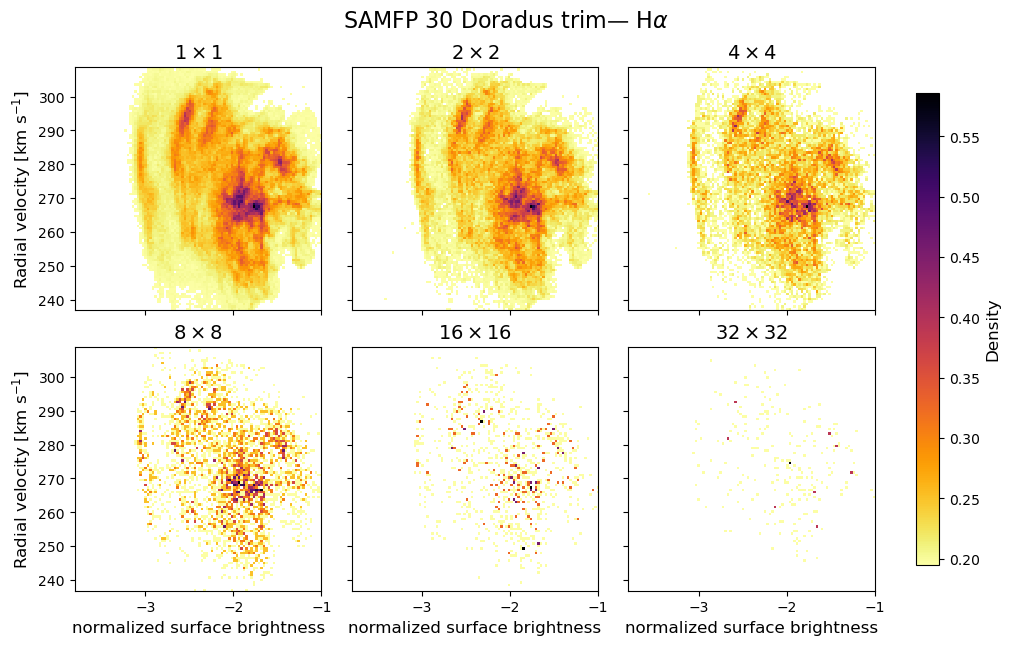

In [14]:
datasets_by_bin = ha_muse

bin_labels = {
    bin_level: rf"${2**bin_level}\times{2**bin_level}$"
    for bin_level in BINS
}

bin_order = list(BINS)

# Surface-brightness range is kept from the original diagnostic.
xrange = [-3.8, -1.0]

# Use one common radial-velocity range for all panels, derived from the
# complete 30 Dor sample. This avoids Orion-specific hard-coded limits.
v_lo, v_hi = np.nanpercentile(processed_data["VV"], [0.5, 99.5])
ypad = 0.05 * (v_hi - v_lo)
yrange = [v_lo - ypad, v_hi + ypad]

nbins_hist = 100

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = axes.flatten()
im = None

for ax, bin_id in zip(axes, bin_order):

    data = datasets_by_bin[bin_id]

    SB = np.asarray(data["SB"])
    VV = np.asarray(data["VV"])

    mask = (
        np.isfinite(SB)
        & np.isfinite(VV)
        & (SB > 0)
    )

    SB_valid = SB[mask]
    VV_valid = VV[mask]

    # Same normalization convention as the original notebook.
    SB_norm = SB_valid / (np.nanmedian(SB_valid) * 100)

    x = np.log10(SB_norm)
    y = VV_valid

    H, xedges, yedges = np.histogram2d(
        x,
        y,
        bins=nbins_hist,
        range=[xrange, yrange],
        density=True,
    )

    HH = np.where(H == 0, np.nan, H)

    im = ax.imshow(
        HH.T,
        origin="lower",
        aspect="auto",
        cmap="inferno_r",
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        interpolation="nearest",
    )

    ax.set_title(bin_labels[bin_id], fontsize=14)
    ax.set_xlim(xrange)
    ax.set_ylim(yrange)
    ax.grid(False)

for idx, ax in enumerate(axes):
    row = idx // 3
    col = idx % 3

    if col == 0:
        ax.set_ylabel(
            r"Radial velocity [km s$^{-1}$]",
            fontsize=12,
        )

    if row == 1:
        ax.set_xlabel(
            r"normalized surface brightness",
            fontsize=12,
        )

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.9,
    pad=0.03,
)

fig.suptitle(
    r"SAMFP 30 Doradus trim— H$\alpha$",
    fontsize=16,
    y=1.05,
)

cbar.set_label("Density", fontsize=12)

fig.savefig(
    FIGS_DIR / "SAMFP_sb_vs_vv_bins_trim.pdf",
    dpi=600,
    bbox_inches="tight",
)

plt.show()


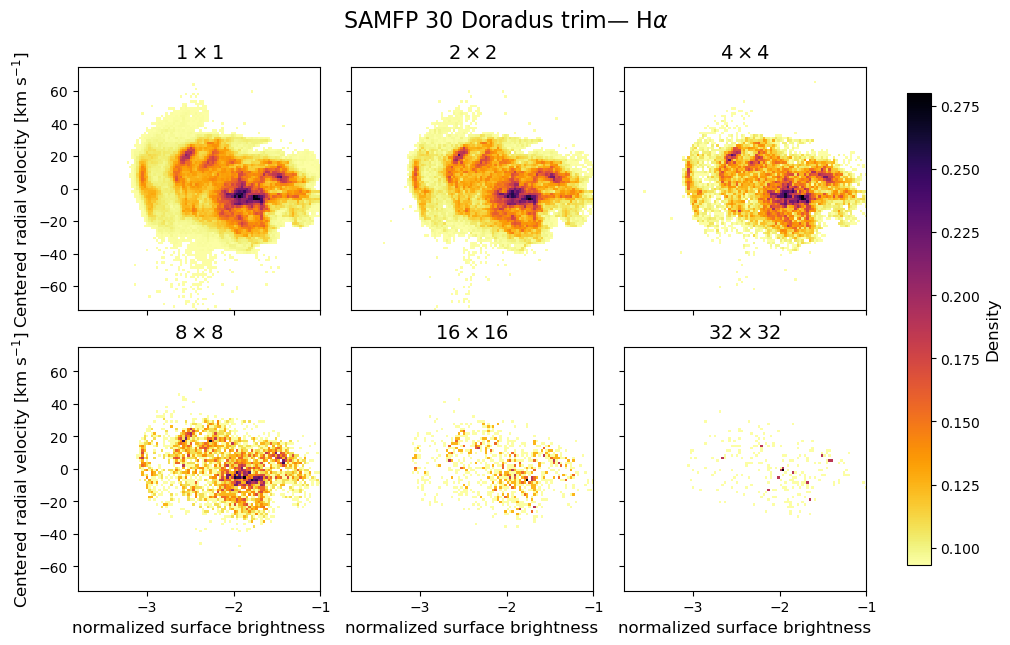

In [13]:
datasets_by_bin = ha_muse

bin_labels = {
    bin_level: rf"${2**bin_level}\times{2**bin_level}$"
    for bin_level in BINS
}

bin_order = list(BINS)

xrange = [-3.8, -1.0]

# Common centered-velocity range for all panels.
rv_lo, rv_hi = np.nanpercentile(processed_data["RV_centered"], [0.5, 99.5])
rv_span = max(abs(rv_lo), abs(rv_hi))
yrange = [-75, 75]

nbins_hist = 100

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = axes.flatten()
im = None

for ax, bin_id in zip(axes, bin_order):

    data = datasets_by_bin[bin_id]

    SB = np.asarray(data["SB"])
    RV = np.asarray(data["RV_centered"])

    mask = (
        np.isfinite(SB)
        & np.isfinite(RV)
        & (SB > 0)
    )

    SB_valid = SB[mask]
    RV_valid = RV[mask]

    SB_norm = SB_valid / (np.nanmedian(SB_valid) * 100)

    x = np.log10(SB_norm)
    y = RV_valid

    H, xedges, yedges = np.histogram2d(
        x,
        y,
        bins=nbins_hist,
        range=[xrange, yrange],
        density=True,
    )

    HH = np.where(H == 0, np.nan, H)

    im = ax.imshow(
        HH.T,
        origin="lower",
        aspect="auto",
        cmap="inferno_r",
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        interpolation="nearest",
    )

    ax.set_title(bin_labels[bin_id], fontsize=14)
    ax.set_xlim(xrange)
    ax.set_ylim(yrange)
    ax.grid(False)

for idx, ax in enumerate(axes):
    row = idx // 3
    col = idx % 3

    if col == 0:
        ax.set_ylabel(
            r"Centered radial velocity [km s$^{-1}$]",
            fontsize=12,
        )

    if row == 1:
        ax.set_xlabel(
            r"normalized surface brightness",
            fontsize=12,
        )

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.9,
    pad=0.03,
)

fig.suptitle(
    r"SAMFP 30 Doradus trim— H$\alpha$",
    fontsize=16,
    y=1.05,
)

cbar.set_label("Density", fontsize=12)

fig.savefig(
    FIGS_DIR / "SAMFP_sb_vs_centered_vv_bins_trim.pdf",
    dpi=600,
    bbox_inches="tight",
)

plt.show()
